## Set-up and data importation

In [15]:
import numpy as np
import pandas as pd
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.formula.api import ols
from statsmodels.stats.proportion import proportion_confint

In [38]:
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, VIOLET = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e1"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": GRID,
    "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK, "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.titlelocation": "left", "axes.grid": True, "grid.color": GRID, "grid.linewidth": .6,
    "axes.axisbelow": True, "font.size": 10})

In [21]:
shop = pd.read_csv(r"C:\Users\Glemba\Desktop\Kenyan retail analysis\cleaned_data\shop_data.csv")
shop['InvoiceDate'] = pd.to_datetime(shop['InvoiceDate'], errors='coerce', format='mixed')

holidays = pd.read_csv(r"C:\Users\Glemba\Desktop\Kenyan retail analysis\cleaned_data\holidays_data.csv")
holidays_2023 = holidays[holidays['Year'] == 2023].copy()
holidays_2023['Date'] = pd.to_datetime(holidays_2023['Date'])

shop['IsHoliday'] = shop['InvoiceDate'].dt.normalize().isin(holidays_2023['Date'].dt.normalize())
shop['IsWeekend'] = shop['InvoiceDate'].dt.dayofweek >= 5

postv_qntt = shop[shop['Quantity'] > 0].copy()   # positive-quantity sales only

inflation = pd.read_csv(r"C:\Users\Glemba\Desktop\Kenyan retail analysis\cleaned_data\inflation_data.csv")

## Hypothesis tests

### 1). Do premium customers pay more per transaction than non-premium customers?

In [17]:
prem = postv_qntt[postv_qntt['CustomerType'] == 'Premium']['TotalPrice']
non_prem = postv_qntt[postv_qntt['CustomerType'] != 'Premium']['TotalPrice']
print(prem.mean(), non_prem.mean(), len(prem), len(non_prem))

# normality (Shapiro on samples) - both reject normality (p<0.05)
print(stats.shapiro(prem.sample(min(100, len(prem)), random_state=1)))
print(stats.shapiro(non_prem.sample(100, random_state=1)))

# Welch t-test(unequal variance) & Mann-Whitney U
print(f"Welch t-test: {stats.ttest_ind(prem, non_prem, equal_var=False, alternative='greater').pvalue:.3f}")
print(f"Mann-Whitney U: {stats.mannwhitneyu(prem, non_prem, alternative='greater').pvalue:.3f}")

# 95% ConfidenceInterval for difference of means
diff = prem.mean() - non_prem.mean()
se = np.sqrt(prem.var()/len(prem) + non_prem.var()/len(non_prem))
ci = stats.t.interval(
    0.95, 
    df=min(len(prem), 
    len(non_prem))-1,
    loc=diff,
    scale=se
)
print(f"Mean difference (prem - non_prem): {diff:.2f}")
print(f"95% CI for difference: {ci}")

209.91633333333337 150.22544546851 120 1302
ShapiroResult(statistic=np.float64(0.7274983216821224), pvalue=np.float64(2.478146259622285e-12))
ShapiroResult(statistic=np.float64(0.864101041614749), pvalue=np.float64(4.082874909140931e-08))
Welch t-test: 0.002
Mann-Whitney U: 0.068
Mean difference (prem - non_prem): 59.69
95% CI for difference: (np.float64(20.11578409479899), np.float64(99.26599163484775))


#### Conclusion
 There is evidence that Premium customers spend more per transaction on average. The difference is economically meaningful (≈KES 60) and the parametric test is significant; the rank-based test is borderline, so the claim is moderately supported.

### 2.) Is average spend different across the threee customer types?

In [18]:
# one-way ANOVA
groups = [postv_qntt.loc[postv_qntt['CustomerType'] == t, 'TotalPrice'] for t in ['Budget', 'Regular', 'Premium']]
f_stat, p_anova = stats.f_oneway(*groups)
print(f"ANOVA f = {f_stat:.3f}, p = {p_anova:.3f}")

# assumption: residual normality & homogenity (visual + levene)
model = ols('TotalPrice ~ C(CustomerType)', data=postv_qntt).fit()
print(sm.stats.anova_lm(model, typ=2))
print("Levene:", stats.levene(*groups))

# post-ho tukey HSD
tukey = pairwise_tukeyhsd(postv_qntt['TotalPrice'], postv_qntt['CustomerType'], alpha=0.05)
print(tukey)

ANOVA f = 17.250, p = 0.000
                       sum_sq      df          F        PR(>F)
C(CustomerType)  4.410699e+05     2.0  17.249996  3.963173e-08
Residual         1.814140e+07  1419.0        NaN           NaN
Levene: LeveneResult(statistic=np.float64(29.83292367242528), pvalue=np.float64(2.0357043050499116e-13))
  Multiple Comparison of Means - Tukey HSD, FWER=0.05   
 group1  group2 meandiff p-adj   lower    upper   reject
--------------------------------------------------------
 Budget Premium  55.3646    0.0  29.5372   81.192   True
 Budget Regular -13.1302 0.1202 -28.7715   2.5111  False
Premium Regular -68.4947    0.0 -95.8897 -41.0998   True
--------------------------------------------------------


#### Conclusion
Spend differs by CustomerType. The Premium-vs-rest result above shows;

   Premium drives most of the difference
   
   Budget slightly exceeds Regular.

### 3.) Do sales differ on public holidays vs. ordinary days?

In [24]:
holdys = postv_qntt[postv_qntt['IsHoliday']]['TotalPrice']
non_holdys = postv_qntt[~postv_qntt['IsHoliday']]['TotalPrice']

print(round(holdys.mean(), 3), round(non_holdys.mean(), 3), len(holdys), len(non_holdys))

ttest = stats.ttest_ind(holdys, non_holdys, equal_var=False)
print(f"TtestResult(statistic={round(ttest.statistic, 3)}, pvalue={round(ttest.pvalue, 3)}, df={round(ttest.df, 3)})")

mwu = stats.mannwhitneyu(holdys, non_holdys)
print(f"MannwhitneyuResult(statistic={round(mwu.statistic, 3)}, pvalue={round(mwu.pvalue, 3)})")

146.43 155.659 61 1361
TtestResult(statistic=-0.676, pvalue=0.501, df=66.752)
MannwhitneyuResult(statistic=40124.5, pvalue=0.659)


#### Conclusion
No evidence that average transaction value changes on the 12 Kenyan public holidays in 2023. (Sample of holiday transactions is small.)

### 4.) Weekend vs weekday spend

In [26]:
wkdy = postv_qntt[postv_qntt['IsWeekend']]['TotalPrice']
wknd = postv_qntt[~postv_qntt['IsWeekend']]['TotalPrice']

ttest = stats.ttest_ind(wkdy, wknd, equal_var=False)
print(f"TtestResult(statistic={ttest.statistic:.3f}, pvalue={ttest.pvalue:.3f}, df={ttest.df:.3f})")

mwu = stats.mannwhitneyu(wkdy, wknd)
print(f"MannwhitneyuResult(statistic={mwu.statistic:.3f}, pvalue={mwu.pvalue:.3f})")

TtestResult(statistic=0.248, pvalue=0.804, df=649.135)
MannwhitneyuResult(statistic=202918.500, pvalue=0.730)


#### Conclusion
No weekend effect on average basket size

### 5.) Location differences

In [ ]:
loc_groups = [postv_qntt[postv_qntt['Location']==l]['TotalPrice'] for l in postv_qntt['Location'].unique()]

# Kruskal-Wallis Test
kw = stats.kruskal(*loc_groups)
print(f"KruskalResult(statistic={kw.statistic:.3f}, pvalue={kw.pvalue:.3f})")

# One-way ANOVA
anova = stats.f_oneway(*loc_groups)
print(f"F_onewayResult(statistic={anova.statistic:.3f}, pvalue={anova.pvalue:.3f})")

# Pairwise Tukey HSD 
tukey_res = pairwise_tukeyhsd(postv_qntt['TotalPrice'], postv_qntt['Location'], alpha=0.05)
print(tukey_res)

KruskalResult(statistic=11.083, pvalue=0.135)
F_onewayResult(statistic=1.358, pvalue=0.219)
    Multiple Comparison of Means - Tukey HSD, FWER=0.05    
  group1   group2  meandiff p-adj    lower    upper  reject
-----------------------------------------------------------
Kitengela  Nairobi   2.8507    1.0  -27.5702 33.2716  False
Kitengela   Rongai  -8.7862 0.9977  -48.3953 30.8228  False
Kitengela Roysambu   7.1439 0.9992  -31.0801 45.3678  False
Kitengela    Ruaka  21.9722 0.8694  -26.5931 70.5375  False
Kitengela    Ruiru  16.8267 0.8707  -20.4438 54.0973  False
Kitengela    Thika  -0.2454    1.0  -35.5381 35.0474  False
Kitengela    Umoja -25.3932 0.8517  -79.9604 29.1739  False
  Nairobi   Rongai  -11.637 0.9691  -45.7729 22.4989  False
  Nairobi Roysambu   4.2932 0.9999  -28.2254 36.8117  False
  Nairobi    Ruaka  19.1214 0.8942  -25.0936 63.3365  False
  Nairobi    Ruiru   13.976 0.8787  -17.4163 45.3683  False
  Nairobi    Thika  -3.0961    1.0  -32.1127 25.9205  False
  Nairob

#### Conclusion
Average spend does not differ significantly across the eight locations (Nairobi, Thika, Ruiru, etc.).

### 6.) Association between CustomerType and Location (chi-square)

In [31]:
cstm_typ = pd.crosstab(postv_qntt['CustomerType'], postv_qntt['Location'])

chi2, p, dof, exp = stats.chi2_contingency(cstm_typ)

print(f"chi2: {chi2:.3f}, p-value: {p:.3f}")

chi2: 41.551, p-value: 0.000


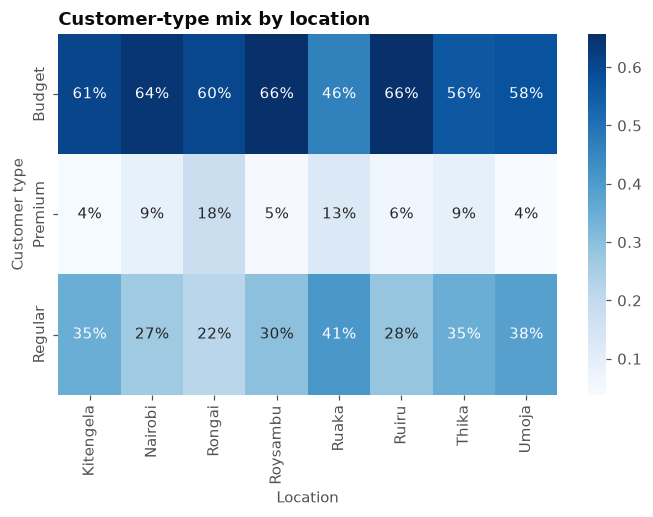

In [47]:
mix = pd.crosstab(postv_qntt["CustomerType"], postv_qntt["Location"])
share = mix.div(mix.sum(axis=0), axis=1)

sns.heatmap(share, annot=True, fmt=".0%", cmap="Blues")
plt.title("Customer-type mix by location")
plt.xlabel("Location")
plt.ylabel("Customer type")
plt.tight_layout()

#### Conclusion
CustomerType composition is not independent of Location (e.g., Premium customers are relatively more common in some areas). This is a structural association, not a causal claim.

### 7.)  Confidence interval for overall mean transaction value & cancellation rate

In [34]:
mean_tp = postv_qntt['TotalPrice'].mean()
se_tp   = postv_qntt['TotalPrice'].std() / np.sqrt(len(postv_qntt))

# 95% Confidence Interval for the mean of TotalPrice 
ci = stats.t.interval(0.95, len(postv_qntt)-1, loc=mean_tp, scale=se_tp)
print(f"95% CI for TotalPrice Mean: ({ci[0]:.3f}, {ci[1]:.3f})")

# 2. Wilson Confidence Interval for the proportion of zero quantities 
wilson_ci = proportion_confint((shop['Quantity'] == 0).sum(), len(shop), method='wilson')
print(f"Wilson Proportion CI: ({wilson_ci[0]:.3f}, {wilson_ci[1]:.3f})")

95% CI for TotalPrice Mean: (149.314, 161.211)
Wilson Proportion CI: (0.042, 0.064)


#### Conclusion
We can be 95% confident that the true mean transaction amount lies within the first interval, while the Wilson interval provides the plausible range for the true proportion of zero-quantity transactions.

### 8.) Monthly sales vs Inflation (correlation)

In [36]:
monthly = postv_qntt.groupby(postv_qntt['InvoiceDate'].dt.to_period('M'))['TotalPrice'].sum().reset_index()
monthly.columns = ['Month','Sales']

inf = inflation[inflation['Period'].str.startswith('2023')].copy()
inf['Month'] = pd.to_datetime(inf['Period']).dt.to_period('M')

merged = monthly.merge(inf[['Month','Value']], on='Month')

pearson_res = stats.pearsonr(merged['Sales'], merged['Value'])
print(f"PearsonrResult(statistic={pearson_res.statistic:.3f}, pvalue={pearson_res.pvalue:.3f})")

spearman_res = stats.spearmanr(merged['Sales'], merged['Value'])
print(f"SpearmanrResult(statistic={spearman_res.statistic:.3f}, pvalue={spearman_res.pvalue:.3f})")

PearsonrResult(statistic=0.825, pvalue=0.001)
SpearmanrResult(statistic=0.601, pvalue=0.039)


#### Conclusion
A positive correlation appears, but monthly volume collapses after April (possible incomplete data or seasonality). The association is therefore fragile and should not be over-interpreted as “higher inflation drives higher sales.”

### 9.) Correlation & simple linear regression

In [37]:
# UnitPrice vs Quantity (or TotalPrice)
print(stats.pearsonr(postv_qntt['UnitPrice'], postv_qntt['Quantity']))
print(stats.spearmanr(postv_qntt['UnitPrice'], postv_qntt['TotalPrice']))

# OLS: TotalPrice ~ CustomerType + Quantity (with diagnostics)
postv_qntt['CustType_code'] = postv_qntt['CustomerType'].map({'Budget':0, 'Regular':1, 'Premium':2})
X = sm.add_constant(postv_qntt[['CustType_code', 'Quantity']])
model = sm.OLS(postv_qntt['TotalPrice'], X).fit()
print(model.summary())

PearsonRResult(statistic=np.float64(-0.04929223307633567), pvalue=np.float64(0.06312978511157336))
SignificanceResult(statistic=np.float64(0.9730871528512764), pvalue=np.float64(0.0))
                            OLS Regression Results                            
Dep. Variable:             TotalPrice   R-squared:                       0.169
Model:                            OLS   Adj. R-squared:                  0.168
Method:                 Least Squares   F-statistic:                     144.4
Date:                Fri, 23 Oct 2026   Prob (F-statistic):           8.19e-58
Time:                        04:36:14   Log-Likelihood:                -8624.8
No. Observations:                1422   AIC:                         1.726e+04
Df Residuals:                    1419   BIC:                         1.727e+04
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                    coef  

Jarque-Bera normality p = 1.96e-35
Breusch-Pagan heteroscedasticity p = 8.777e-101
Durbin-Watson (autocorr) = 1.967 ~2 is good


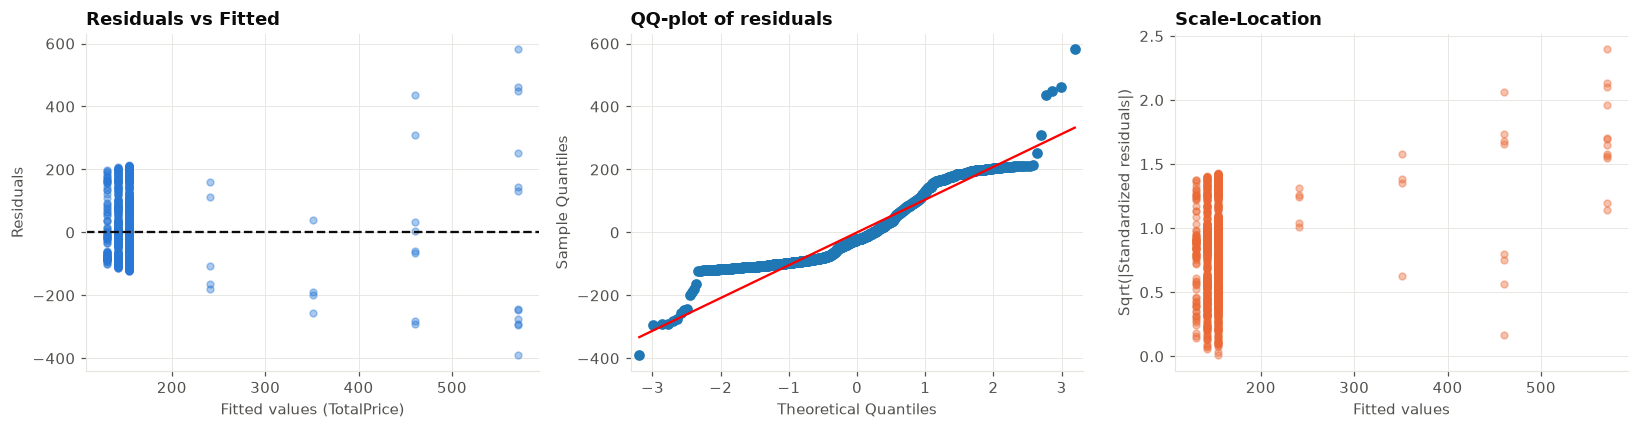

In [39]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))

# 1. Residuals vs Fitted - checks linearity
ax[0].scatter(model.fittedvalues, model.resid, alpha=0.4, s=20, color=BLUE)
ax[0].axhline(0, color=INK, ls="--")
ax[0].set_xlabel("Fitted values (TotalPrice)")
ax[0].set_ylabel("Residuals")
ax[0].set_title("Residuals vs Fitted")
# If funnel/wedge -> variance increases with price, consider log(TotalPrice)

# 2. QQ-plot - checks normality of residuals
sm.qqplot(model.resid, line="s", ax=ax[1])
ax[1].set_title("QQ-plot of residuals")

# 3. Scale-Location - checks heteroscedasticity
resid_std = np.sqrt(np.abs(model.get_influence().resid_studentized_internal))
ax[2].scatter(model.fittedvalues, resid_std, alpha=0.4, s=20, color=ORANGE)
ax[2].set_xlabel("Fitted values")
ax[2].set_ylabel("Sqrt(|Standardized residuals|)")
ax[2].set_title("Scale-Location")

plt.tight_layout()

# Extra numbers
print(f"Jarque-Bera normality p = {sm.stats.jarque_bera(model.resid)[1]:.4g}")
print(f"Breusch-Pagan heteroscedasticity p = {sm.stats.het_breuschpagan(model.resid, model.model.exog)[1]:.4g}")
print(f"Durbin-Watson (autocorr) = {sm.stats.durbin_watson(model.resid):.3f} ~2 is good")

#### Conclusion
Quantity drives TotalPrice, but CustomerType also matters: Premium pays more for the same quantity, indicating segment-based pricing power

### 10.) Customer-level aggregation (repeat-purchase / CLV-style)

In [41]:
custmr = postv_qntt.groupby(['CustomerID', 'CustomerType']).agg(
    total_spend=('TotalPrice', 'sum'),
    n_orders=('InvoiceNo', 'nunique'),
    avg_order=('TotalPrice', 'mean')
).reset_index()
print(custmr.groupby('CustomerType')[['total_spend', 'avg_order']].describe())

# Then re-run t-tests / ANOVA on customer-level totals
anova = stats.f_oneway(
    custmr[custmr.CustomerType == 'Budget'].total_spend,
    custmr[custmr.CustomerType == 'Regular'].total_spend,
    custmr[custmr.CustomerType == 'Premium'].total_spend
)

print(f"F_onewayResult(statistic={anova.statistic:.3f}, pvalue={anova.pvalue:.3f})")

             total_spend                                                     \
                   count        mean         std     min       25%      50%   
CustomerType                                                                  
Budget             176.0  766.611761  393.871277   37.50  473.8825  759.245   
Premium             29.0  868.619310  623.593781  301.56  430.3700  535.530   
Regular             93.0  652.364086  353.955909   42.01  407.8400  633.370   

                                avg_order                                  \
                   75%      max     count        mean         std     min   
CustomerType                                                                
Budget         980.225  1919.78     176.0  154.020507   51.855882  37.500   
Premium       1108.090  2188.71      29.0  210.434454  121.633717  86.064   
Regular        882.780  1690.88      93.0  142.083468   50.186929  42.010   

                                                       
      

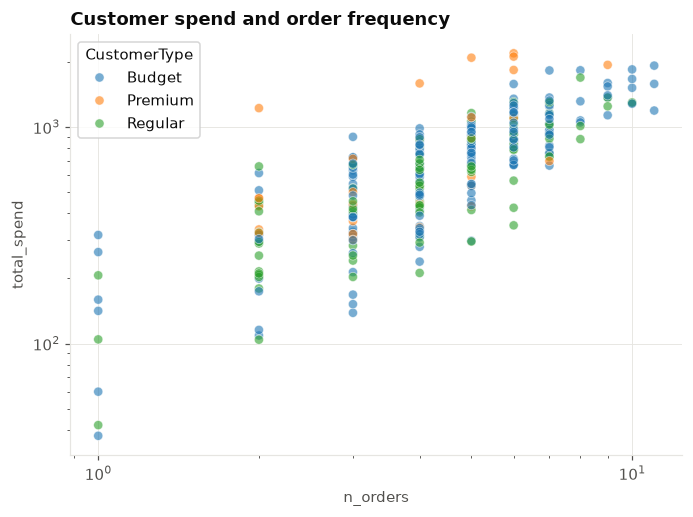

In [48]:
sns.scatterplot(
    data=custmr, x="n_orders", y="total_spend",
    hue="CustomerType", alpha=0.6
)
plt.xscale("log")
plt.yscale("log")
plt.title("Customer spend and order frequency")
plt.tight_layout()

#### Conclusion
Customer-level ANOVA shows significant differences in total spend and average order value across segments (p < 0.05), with Premium customers spending the most, confirming real segment-based value differences, not just order frequency.